# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Triển khai theo `GUIDE.md`, dùng siêu tham số trong `configs/`.

**Chạy riêng E1/E2/E3:** chạy phần 0–2, ô định nghĩa hàm ở phần 3 (có thể bỏ qua
ô chạy E0 và ô chấm E0), rồi phần 4–5. Chọn `RUN_SETUP` ở phần 5 và chạy ô
huấn luyện ở phần 6. Ở phần 7, chọn `EVAL_SETUP` để nạp checkpoint và chấm riêng
thí nghiệm đó; không cần chạy lại phần 6 nếu checkpoint đã có.
Các ô định nghĩa hàm phần 6–7 cũng được dùng ở phần 8. Phần 8 chỉ thực hiện E4.
Dữ liệu, checkpoint và kết quả được ghi tương đối với thư mục gốc repo.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0. Môi trường (Colab T4)

In [3]:
# Runtime → Change runtime type → T4 GPU
!nvidia-smi -L
!pip -q install -r requirements-colab.txt

GPU 0: Tesla T4 (UUID: GPU-39fe1cb3-9da1-596b-ce47-69d60cb3d5fb)


In [4]:
# Kaggle: dùng Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY). KHÔNG viết khoá vào notebook.
import os
from google.colab import userdata
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

## 1. Dữ liệu: tải và chia split

In [5]:
!python scripts/prepare_data.py --kaggle

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:02<00:00, 91.2MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


train: 1422 ảnh, 3515 box, 13 session; pothole=1074, crack=1750, manhole=691
val: 276 ảnh, 639 box, 2 session; pothole=66, crack=470, manhole=103
test: 311 ảnh, 583 box, 3 session; pothole=121, crack=299, manhole=163
{
  "image_id": "20250216_164325",
  "image_path": "images/20250216_164325.jpg",
  "width": 640,
  "height": 360,
  "session": "phone-20250216",
  "objects": [
    {
      "label": "manhole",
      "yolo": [
        0.466407,
        0.552778,
        0.298437,
        0.144444
      ]
    },
    {
      "label": "pothole",
      "yolo": [
        0.604688,
        0.556944,
        0.043751,
        0.113889
      ]
    },
    {
      "label": "pothole",
      "yolo": [
        0.285156,
        0.544444,
        0.051562,
        0.055555
      ]
    },
    {
      "label": "pothole",
      "yolo": [
        0.3875,
        0.498611,
        0.053124,
        0.047222
      ]
    },
    {
      "label": "crack",
      "yolo": [
        0.421875,
        0.672222,
       

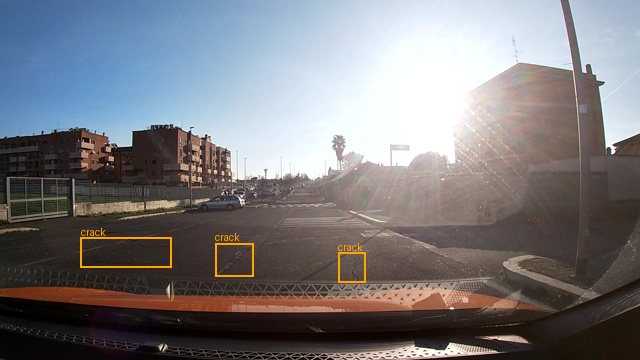

vlcsnap-00128 | session: num-2


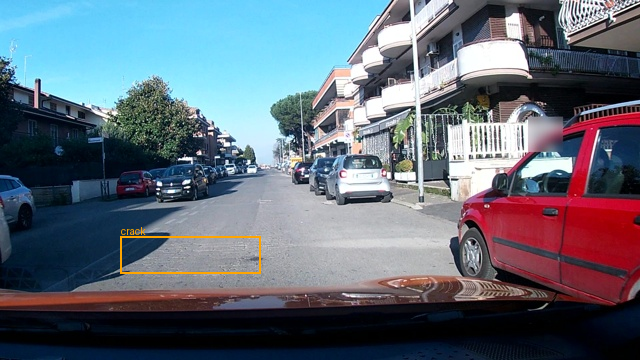

20250219_170531 | session: phone-20250219


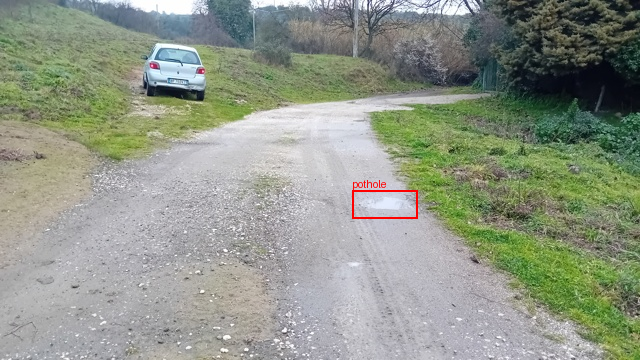

vlcsnap-2025-02-19-14h13m38s815 | session: vlc-2025-02-19-14


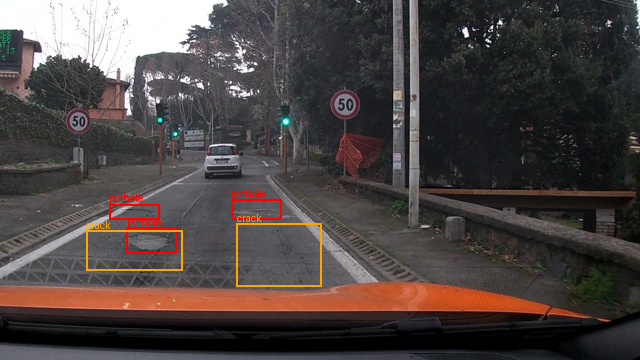

vlcsnap-2025-02-19-14h04m31s687 | session: vlc-2025-02-19-14


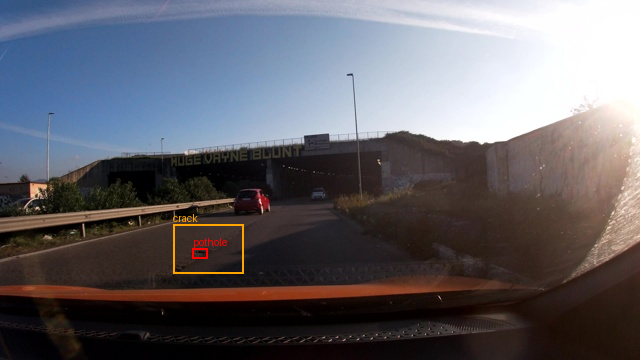

vlcsnap-2025-02-19-13h55m14s182 | session: vlc-2025-02-19-13


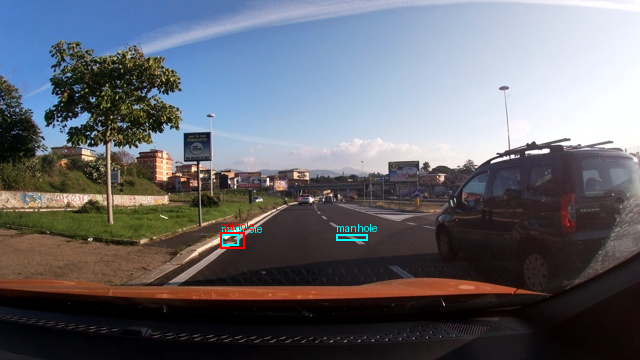

In [6]:
import json
import random
from collections import Counter
from pathlib import Path

from PIL import Image, ImageDraw
from IPython.display import display
from scripts.labcommon import CLASSES, read_jsonl

DATA_DIR = Path("data")
WORK_DIR = Path("work")
EVIDENCE_DIR = Path("report/evidence")
splits = {name: read_jsonl(DATA_DIR / "splits" / f"{name}.jsonl")
          for name in ("train", "val", "test")}
train_samples = splits["train"]
session_sets = {}
for name, rows in splits.items():
    counts = Counter(o["label"] for row in rows for o in row["objects"])
    session_sets[name] = {row["session"] for row in rows}
    print(f"{name}: {len(rows)} ảnh, {sum(counts.values())} box, "
          f"{len(session_sets[name])} session; "
          + ", ".join(f"{label}={counts[label]}" for label in CLASSES))
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    assert not session_sets[a] & session_sets[b], f"Trùng session: {a}/{b}"
assert train_samples, "Split train rỗng. Hãy chạy phần chuẩn bị dữ liệu."
print(json.dumps(train_samples[0], ensure_ascii=False, indent=2))

COLORS = {"pothole": "red", "crack": "orange", "manhole": "cyan"}

def open_image(sample):
    with Image.open(DATA_DIR / sample["image_path"]) as source:
        image = source.convert("RGB")
    assert image.size == (sample["width"], sample["height"])
    return image

def draw_sample(sample):
    image = open_image(sample)
    width, height = image.size
    draw = ImageDraw.Draw(image)
    for obj in sample["objects"]:
        xc, yc, w, h = obj["yolo"]
        box = [(xc - w / 2) * width, (yc - h / 2) * height,
               (xc + w / 2) * width, (yc + h / 2) * height]
        color = COLORS[obj["label"]]
        draw.rectangle(box, outline=color, width=2)
        draw.text((box[0], max(0, box[1] - 12)), obj["label"], fill=color)
    return image

for sample in random.Random(42).sample(train_samples, min(6, len(train_samples))):
    print(sample["image_id"], "| session:", sample["session"])
    display(draw_sample(sample))

## 2. Nhãn: YOLO → JSON thang 0–1000

Prompt: Detect every pothole, crack and manhole in this road image. Return ONLY a JSON list, without markdown or explanation. Each item must have the format {"label":"pothole","bbox_2d":[x1,y1,x2,y2]}. The only allowed labels are pothole, crack, manhole. Use integer coordinates on a 0–1000 scale, normalized by image width and height; x1 < x2 and y1 < y2. Order boxes top to bottom, then left to right. Return [] if no objects exist.
Answer: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]


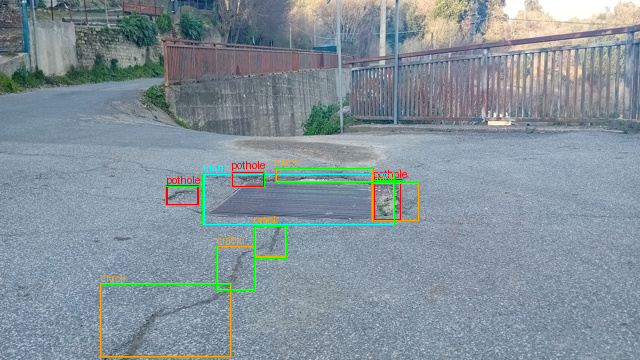

In [7]:
def yolo_to_box(label, yolo, coord="norm1000", width=None, height=None):
    if label not in CLASSES:
        raise ValueError(f"Lớp không hợp lệ: {label}")
    if coord == "norm1000":
        sx = sy = 1000
    elif coord == "pixel" and width and height:
        sx, sy = width, height
    else:
        raise ValueError("coord phải là norm1000 hoặc pixel (có width/height).")
    xc, yc, w, h = yolo
    xyxy = ((xc - w / 2) * sx, (yc - h / 2) * sy,
            (xc + w / 2) * sx, (yc + h / 2) * sy)
    box = [int(max(0, min(limit, round(value))))
           for value, limit in zip(xyxy, (sx, sy, sx, sy))]
    return {"label": label, "bbox_2d": box}

def objects_to_answer(objects, coord="norm1000", width=None, height=None):
    boxes = [yolo_to_box(o["label"], o["yolo"], coord, width, height)
             for o in objects]
    boxes.sort(key=lambda o: (o["bbox_2d"][1], o["bbox_2d"][0]))
    return json.dumps(boxes, ensure_ascii=False, separators=(",", ":"))

def make_prompt(coord="norm1000", width=None, height=None):
    if coord == "norm1000":
        scale = "integer coordinates on a 0–1000 scale, normalized by image width and height"
    elif coord == "pixel" and width and height:
        scale = (f"integer pixel coordinates in the original {width}×{height} image, "
                 f"x in [0,{width}] and y in [0,{height}]")
    else:
        raise ValueError("Thang toạ độ không hợp lệ hoặc thiếu kích thước ảnh.")
    return ("Detect every pothole, crack and manhole in this road image. "
            "Return ONLY a JSON list, without markdown or explanation. "
            'Each item must have the format {"label":"pothole","bbox_2d":[x1,y1,x2,y2]}. '
            "The only allowed labels are pothole, crack, manhole. "
            f"Use {scale}; x1 < x2 and y1 < y2. "
            "Order boxes top to bottom, then left to right. Return [] if no objects exist.")

PROMPT = make_prompt()
sample = train_samples[0]
answer = objects_to_answer(sample["objects"])
print("Prompt:", PROMPT)
print("Answer:", answer)
assert objects_to_answer([]) == "[]"
# YOLO gốc màu đỏ/cam/cyan; JSON quy ngược về pixel màu xanh lá.
image = draw_sample(sample)
draw = ImageDraw.Draw(image)
for obj in json.loads(answer):
    x1, y1, x2, y2 = obj["bbox_2d"]
    draw.rectangle((x1 / 1000 * image.width, y1 / 1000 * image.height,
                    x2 / 1000 * image.width, y2 / 1000 * image.height),
                   outline="lime", width=1)
display(image)

## 3. E0: zero-shot

Ô sau chỉ định nghĩa hàm dùng chung. Ô `run_e0()` mới tải model và chạy E0;
có thể bỏ qua ô đó cùng lệnh chấm E0 khi chỉ chạy E1/E2/E3.
API model/processor đối chiếu với [tài liệu Qwen3-VL của Hugging Face](https://huggingface.co/docs/transformers/model_doc/qwen3_vl).

**Sửa lỗi ViT 4-bit ở E2/E3:** dùng `model.visual` trong danh sách skip vì
Transformers 5.19 khớp tên đầy đủ/prefix của module. Hàm nạp model kiểm tra
ViT, cả hai nhóm projector và `lm_head` trước khi train hoặc nạp adapter.
Sau khi cập nhật notebook, restart runtime để giải phóng model cũ; chạy lại
các ô dùng chung phần 0–5 (bỏ qua ô chạy/chấm E0), ô định nghĩa hàm phần 6,
chọn `RUN_SETUP="E2"` rồi chạy ô train. Log phải báo ViT/projector không
lượng tử hoá. Projector được chuyển sang fp32 khi setup E2/E3.
Tham khảo [mã so khớp của Transformers 5.19](https://github.com/huggingface/transformers/blob/v5.19.0/src/transformers/quantizers/quantizers_utils.py#L24).


In [8]:
import gc
import torch
import yaml
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3VLForConditionalGeneration

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

def require_cuda():
    if not torch.cuda.is_available():
        raise RuntimeError("Cần GPU CUDA. Trên Colab hãy chọn runtime T4.")

def release_cuda():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def load_processor(model_id=MODEL_ID):
    processor = AutoProcessor.from_pretrained(model_id)
    processor.tokenizer.padding_side = "left"
    if processor.tokenizer.pad_token_id is None:
        processor.tokenizer.pad_token = processor.tokenizer.eos_token
    return processor

def verify_base_precision(model, verbose=True):
    import bitsandbytes as bnb

    # Kiểm tra cả lớp và kiểu Parameter: Params4bit có thể vẫn có dtype float
    # trước khi được pack, nên chỉ kiểm tra dtype là chưa đủ.
    quantized_types = (bnb.nn.Linear4bit, bnb.nn.Linear8bitLt)
    quantized_params = (bnb.nn.Params4bit, bnb.nn.Int8Params)
    protected = [(name, module) for name, module in model.named_modules()
                 if "visual" in name.split(".") or name.split(".")[-1] == "lm_head"]
    if not any("visual" in name.split(".") for name, _ in protected):
        raise RuntimeError("Không tìm thấy ViT trong model; kiểm tra cây named_modules().")
    bad_modules = [name for name, module in protected if isinstance(module, quantized_types)]
    bad_params = []
    wrong_dtype = []
    for name, module in protected:
        for key, param in module.named_parameters(recurse=False):
            full_name = f"{name}.{key}"
            if isinstance(param, quantized_params):
                bad_params.append(full_name)
            elif param.dtype != torch.float16:
                wrong_dtype.append(f"{full_name}: {param.dtype}")
    if bad_modules or bad_params:
        examples = (bad_modules + bad_params)[:5]
        raise RuntimeError(
            "ViT/lm_head vẫn bị lượng tử hoá: " + ", ".join(examples)
            + ". Hãy nạp lại model với llm_int8_skip_modules=['model.visual', 'lm_head'] "
            "ở ô định nghĩa hàm phần 3. Không dùng .float() để sửa Params4bit."
        )
    if wrong_dtype:
        raise RuntimeError("ViT/lm_head phải là fp16 trước khi setup: " + ", ".join(wrong_dtype[:5]))
    llm_4bit = [name for name, module in model.named_modules()
                if "language_model" in name.split(".") and isinstance(module, bnb.nn.Linear4bit)]
    if not llm_4bit:
        raise RuntimeError("LLM chưa có Linear4bit; kiểm tra cấu hình NF4 của model gốc.")
    if verbose:
        print(f"Kiểm tra lượng tử hoá: LLM có {len(llm_4bit)} Linear4bit; "
              "ViT/projector/lm_head không lượng tử hoá, trọng số fp16.")


def load_base_model(model_id=MODEL_ID):
    require_cuda()
    quantization = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True,
        # Transformers 5.19 so khớp theo đường dẫn đầy đủ/prefix.
        # "visual" không khớp "model.visual.blocks...".
        llm_int8_skip_modules=["model.visual", "lm_head"],
    )
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        model_id, quantization_config=quantization, dtype=torch.float16,
        device_map={"": 0}, attn_implementation="sdpa",
    )
    verify_base_precision(model)
    return model

def user_message(image, prompt):
    return {"role": "user", "content": [
        {"type": "image", "image": image}, {"type": "text", "text": prompt}]}

def predict_to_jsonl(model, processor, rows, out_path, coord="norm1000",
                     batch_size=4, max_new_tokens=256):
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    model.eval()
    model.config.use_cache = True
    model.config.text_config.use_cache = True
    if hasattr(model, "gradient_checkpointing_disable"):
        model.gradient_checkpointing_disable()
    with out_path.open("w", encoding="utf-8") as stream, torch.inference_mode():
        for start in range(0, len(rows), batch_size):
            chunk = rows[start:start + batch_size]
            messages = [[user_message(open_image(row), make_prompt(
                coord, row["width"], row["height"]))] for row in chunk]
            inputs = processor.apply_chat_template(
                messages, tokenize=True, add_generation_prompt=True,
                return_dict=True, return_tensors="pt", padding=True,
            )
            inputs.pop("token_type_ids", None)
            inputs = inputs.to(model.device)
            # Autocast cũng cần khi projector đã được nạp ở float32 (E2/E3).
            with torch.autocast("cuda", dtype=torch.float16):
                generated = model.generate(
                    **inputs, max_new_tokens=max_new_tokens, do_sample=False,
                    pad_token_id=processor.tokenizer.pad_token_id,
                )
            raw = processor.batch_decode(
                generated[:, inputs["input_ids"].shape[1]:],
                skip_special_tokens=True, clean_up_tokenization_spaces=False,
            )
            for row, text in zip(chunk, raw):
                stream.write(json.dumps({"image_id": row["image_id"], "raw": text},
                                        ensure_ascii=False) + "\n")
            stream.flush()
            print(f"{out_path.name}: {min(start + batch_size, len(rows))}/{len(rows)} ảnh")
            del inputs, generated
    return out_path

def run_e0():
    cfg = yaml.safe_load(Path("configs/e0.yaml").read_text())
    model = None
    try:
        model = load_base_model(cfg["model_id"])
        return predict_to_jsonl(model, load_processor(cfg["model_id"]), splits["test"],
                                WORK_DIR / "e0.jsonl", max_new_tokens=cfg["max_new_tokens"])
    finally:
        del model
        release_cuda()

In [ ]:
run_e0()
for row in read_jsonl(WORK_DIR / "e0.jsonl")[:5]:
    print(row["image_id"], "=>", row["raw"])

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

In [ ]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

In [ ]:
e0_score = json.loads((EVIDENCE_DIR / "e0.json").read_text())
print("E0 parse_valid_rate:", e0_score["parse_valid_rate"])

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [9]:
from torch.utils.data import Dataset, DataLoader

def encode_example(image, prompt, answer, processor):
    user = user_message(image, prompt)
    prompt_enc = processor.apply_chat_template(
        [user], tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt",
    )
    full_enc = processor.apply_chat_template(
        [user, {"role": "assistant", "content": [{"type": "text", "text": answer}]}],
        tokenize=True, add_generation_prompt=False,
        return_dict=True, return_tensors="pt",
    )
    full_enc.pop("token_type_ids", None)
    n = prompt_enc["input_ids"].shape[1]
    assert torch.equal(full_enc["input_ids"][0, :n], prompt_enc["input_ids"][0]), (
        "Prompt không phải tiền tố của full chat. Kiểm tra chat template.")
    labels = full_enc["input_ids"].clone()
    labels[:, :n] = -100
    full_enc["labels"] = labels
    assert (labels != -100).any(), "Không có token đáp án để học."
    return dict(full_enc)

def collate(batch, processor):
    # Left padding nhất quán với processor; ảnh/grid nối theo thứ tự mẫu.
    length = max(item["input_ids"].shape[1] for item in batch)
    out = {}
    sequence_pads = {"input_ids": processor.tokenizer.pad_token_id,
                     "attention_mask": 0, "mm_token_type_ids": 0, "labels": -100}
    for key, value in sequence_pads.items():
        if not any(key in item for item in batch):
            continue
        assert all(key in item for item in batch), f"Thiếu {key} ở một mẫu."
        out[key] = torch.cat([torch.nn.functional.pad(
            item[key], (length - item[key].shape[1], 0), value=value)
            for item in batch], dim=0)
    for key in ("pixel_values", "image_grid_thw"):
        out[key] = torch.cat([item[key] for item in batch], dim=0)
    assert (out["labels"][out["attention_mask"] == 0] == -100).all()
    return out

class RoadDataset(Dataset):
    def __init__(self, rows, processor, coord="norm1000"):
        self.rows, self.processor, self.coord = rows, processor, coord

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        return encode_example(
            open_image(row), make_prompt(self.coord, row["width"], row["height"]),
            objects_to_answer(row["objects"], self.coord, row["width"], row["height"]),
            self.processor,
        )

# Kiểm tra mask trước khi huấn luyện; chỉ tải processor, chưa tải model.
processor = load_processor()
sample = next((row for row in train_samples
               if (row["width"], row["height"]) == (640, 360)), train_samples[0])
answer = objects_to_answer(sample["objects"])
encoded = encode_example(open_image(sample), PROMPT, answer, processor)
image_token_id = processor.tokenizer.convert_tokens_to_ids("<|image_pad|>")
image_tokens = int((encoded["input_ids"] == image_token_id).sum())
print("Số token ảnh:", image_tokens)
if (sample["width"], sample["height"]) == (640, 360):
    assert image_tokens == 220, "Kiểm tra cấu hình resize của processor."
supervised = encoded["input_ids"][encoded["labels"] != -100]
decoded_answer = processor.tokenizer.decode(supervised, skip_special_tokens=False)
print("Token được tính loss:", decoded_answer)
assert decoded_answer.strip() == answer + "<|im_end|>"
assert (encoded["labels"][encoded["input_ids"] == image_token_id] == -100).all()
del encoded

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

Số token ảnh: 220
Token được tính loss: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>



## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [10]:
import re
from copy import deepcopy
from peft import LoraConfig, PeftModel, get_peft_model

def experiment_config(setup):
    if setup not in ("E1", "E2", "E3"):
        raise ValueError("Chọn E1, E2 hoặc E3.")
    cfg = yaml.safe_load(Path(f"configs/{setup.lower()}.yaml").read_text())
    cfg.update(setup=setup, coord="norm1000", train_fraction=1.0,
               max_new_tokens=256, warmup_ratio=0.05, weight_decay=0.0)
    return cfg

LLM_TARGETS = (r"model\.language_model\.layers\.\d+\."
               r"(?:self_attn\.(?:q_proj|k_proj|v_proj|o_proj)|mlp\.(?:gate_proj|up_proj|down_proj))")
VIT_TARGETS = (r"model\.visual\.blocks\.\d+\."
               r"(?:attn\.(?:qkv|proj)|mlp\.(?:linear_fc1|linear_fc2))")

def is_projector(name):
    return "visual.merger." in name or "visual.deepstack_merger_list." in name

def apply_setup(model, setup, cfg=None):
    cfg = experiment_config(setup) if cfg is None else cfg
    assert cfg["setup"] == setup
    # Kiểm tra trước khi bật gradient/cast projector, kể cả model nạp từ ô cũ.
    verify_base_precision(model, verbose=False)
    for param in model.parameters():
        param.requires_grad_(False)
    # Giữ ViT/lm_head fp16; không gọi prepare_model_for_kbit_training vì hàm
    # đó có thể cast toàn bộ trọng số không lượng tử hoá sang fp32.
    model.enable_input_require_grads()
    target_regex = LLM_TARGETS if setup != "E3" else f"(?:{LLM_TARGETS}|{VIT_TARGETS})"
    module_names = [name for name, _ in model.named_modules()]
    matched_modules = [name for name in module_names if re.fullmatch(target_regex, name)]
    print("Các module LoRA khớp trên model thật:")
    print("\n".join(matched_modules))
    expected = 348 if setup == "E3" else 252
    assert len(matched_modules) == expected, (len(matched_modules), expected)
    model = get_peft_model(model, LoraConfig(
        r=cfg["lora"]["r"], lora_alpha=cfg["lora"]["alpha"],
        lora_dropout=cfg["lora"]["dropout"], target_modules=target_regex,
        bias="none", task_type="CAUSAL_LM",
    ))
    projector_count = 0
    for name, param in model.named_parameters():
        if cfg["train_projector"] and is_projector(name):
            param.data = param.data.to(torch.float32)
            param.requires_grad_(True)
            projector_count += param.numel()
        elif param.requires_grad:
            # GradScaler không unscale gradient fp16; giữ LoRA trainable fp32.
            assert "lora_" in name, f"Tham số ngoài setup: {name}"
            param.data = param.data.to(torch.float32)
    if cfg["train_projector"]:
        assert 100_000_000 < projector_count < 120_000_000, projector_count
    model.print_trainable_parameters()
    print(f"Projector trainable: {projector_count:,} (E2/E3 thêm khoảng 109M so với E1)")
    return model, matched_modules

In [11]:
# Chọn một setup; mỗi lần huấn luyện đều nạp model gốc mới để tránh lẫn adapter.
RUN_SETUP = "E3"  # đổi thành "E2" hoặc "E3" và chạy lại ô này + ô train phần 6
RUN_CONFIG = experiment_config(RUN_SETUP)
# Nếu OOM trên T4: đổi cùng một cấu hình cho E1/E2/E3 để so sánh công bằng.
# RUN_CONFIG.update(batch_size=1, grad_accum=8)
print(json.dumps(RUN_CONFIG, ensure_ascii=False, indent=2))

{
  "name": "E3",
  "description": "E2 + LoRA trên các khối attention và MLP của ViT.",
  "model_id": "Qwen/Qwen3-VL-4B-Instruct",
  "quantization": "nf4-4bit",
  "lora": {
    "r": 16,
    "alpha": 32,
    "dropout": 0.05,
    "targets": "llm+vit"
  },
  "train_projector": true,
  "lr": 0.0002,
  "batch_size": 2,
  "grad_accum": 4,
  "max_steps": 300,
  "seed": 42,
  "setup": "E3",
  "coord": "norm1000",
  "train_fraction": 1.0,
  "max_new_tokens": 256,
  "warmup_ratio": 0.05,
  "weight_decay": 0.0
}


## 6. Vòng huấn luyện

Chạy ô định nghĩa hàm một lần, rồi ô `train_experiment(...)` cho setup đã chọn.
Checkpoint ở `work/<tên>/checkpoint-100`, `checkpoint-200`, `checkpoint-300`
và `work/<tên>/final`. Mỗi checkpoint chứa adapter, `extra_trainable.pt` (E2/E3),
processor và `run.json`. Để sao lưu, mount Drive rồi đặt `DRIVE_BACKUP_DIR`;
mỗi checkpoint sẽ được chép vào đó. Checkpoint dùng để suy luận, không chứa
optimizer/scaler nên chạy lại ô train sẽ bắt đầu một lượt huấn luyện mới.

In [12]:
import math
import shutil
import time
from functools import partial
from transformers import get_cosine_schedule_with_warmup, set_seed

DRIVE_BACKUP_DIR = Path("/content/drive/MyDrive/day10-checkpoints")

def save_checkpoint(model, processor, destination, run):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(destination)
    processor.save_pretrained(destination)
    extra = {name: param.detach().cpu().clone()
             for name, param in model.named_parameters()
             if param.requires_grad and is_projector(name)}
    if run["config"]["train_projector"]:
        assert extra, "E2/E3 phải lưu cả projector."
        torch.save(extra, destination / "extra_trainable.pt")
    (destination / "run.json").write_text(
        json.dumps(run, ensure_ascii=False, indent=2), encoding="utf-8")
    if DRIVE_BACKUP_DIR is not None:
        backup = Path(DRIVE_BACKUP_DIR) / destination.parent.name / destination.name
        shutil.copytree(destination, backup, dirs_exist_ok=True)
    print("Đã lưu:", destination)

def train_experiment(cfg):
    cfg = deepcopy(cfg)
    require_cuda()
    release_cuda()
    set_seed(cfg["seed"])
    fraction = cfg["train_fraction"]
    assert 0 < fraction <= 1
    rows = list(splits["train"])
    # Cùng seed: subset 10% cố định, không lấy thêm ảnh val/test.
    if fraction < 1:
        rows = random.Random(cfg["seed"]).sample(rows, max(1, int(len(rows) * fraction)))
    assert rows and cfg["max_steps"] > 0 and cfg["grad_accum"] > 0
    run_dir = WORK_DIR / cfg["name"].lower()
    model = optimizer = scheduler = loader = iterator = params = None
    batch = output = loss = None
    started = None
    try:
        processor = load_processor(cfg["model_id"])
        model, matched = apply_setup(load_base_model(cfg["model_id"]), cfg["setup"], cfg)
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        model.config.use_cache = False
        model.config.text_config.use_cache = False
        model.train()
        params = [p for p in model.parameters() if p.requires_grad]
        assert all(p.dtype == torch.float32 for p in params)
        loader = DataLoader(
            RoadDataset(rows, processor, cfg["coord"]), batch_size=cfg["batch_size"],
            shuffle=True, num_workers=0, collate_fn=partial(collate, processor=processor),
            generator=torch.Generator().manual_seed(cfg["seed"]),
        )
        iterator = iter(loader)
        optimizer = torch.optim.AdamW(params, lr=float(cfg["lr"]),
                                      weight_decay=cfg["weight_decay"])
        scheduler = get_cosine_schedule_with_warmup(
            optimizer, num_warmup_steps=math.ceil(cfg["max_steps"] * cfg["warmup_ratio"]),
            num_training_steps=cfg["max_steps"],
        )
        scaler = torch.amp.GradScaler("cuda")
        optimizer.zero_grad(set_to_none=True)
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        started = time.perf_counter()
        history = []
        step = attempts = 0
        while step < cfg["max_steps"]:
            loss_sum = 0.0
            for _ in range(cfg["grad_accum"]):
                try:
                    batch = next(iterator)
                except StopIteration:
                    iterator = iter(loader)
                    batch = next(iterator)
                batch = {key: tensor.to(model.device) for key, tensor in batch.items()}
                with torch.autocast("cuda", dtype=torch.float16):
                    output = model(**batch)
                    loss = output.loss / cfg["grad_accum"]
                if not torch.isfinite(loss).item():
                    raise FloatingPointError(
                        f"{cfg['name']} loss NaN/Inf ở bước {step + 1}; dừng. "
                        "Kiểm tra mask, giảm lr hoặc batch_size theo GUIDE.")
                loss_sum += loss.detach().float().item()
                scaler.scale(loss).backward()
                del output, loss, batch
                output = loss = batch = None
            scaler.unscale_(optimizer)
            grad_norm = torch.nn.utils.clip_grad_norm_(params, 1.0)
            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            attempts += 1
            if scaler.get_scale() < old_scale:
                # AMP bỏ qua update khi gradient tràn; không đếm là bước tối ưu.
                print("AMP bỏ qua update do gradient overflow; scale =", scaler.get_scale())
                if attempts - step > 30:
                    raise FloatingPointError("Gradient overflow lặp lại; hãy giảm lr.")
                continue
            scheduler.step()
            step += 1
            history.append({"step": step, "loss": loss_sum,
                            "lr": scheduler.get_last_lr()[0], "grad_norm": float(grad_norm)})
            if step == 1 or step % 10 == 0:
                print(f"{cfg['name']} step {step}/{cfg['max_steps']}: loss={loss_sum:.4f}")
            if step % 100 == 0 or step == cfg["max_steps"]:
                torch.cuda.synchronize()
                run = {"name": cfg["name"], "setup": cfg["setup"], "config": cfg,
                       "step": step, "n_train_images": len(rows),
                       "matched_modules": matched,
                       "trainable_params": sum(p.numel() for p in params),
                       "peak_vram_gb": torch.cuda.max_memory_allocated() / 1024**3,
                       "train_minutes": (time.perf_counter() - started) / 60,
                       "loss_history": history}
                save_checkpoint(model, processor, run_dir / f"checkpoint-{step}", run)
        save_checkpoint(model, processor, run_dir / "final", run)
        (run_dir / "run.json").write_text(json.dumps(run, ensure_ascii=False, indent=2),
                                           encoding="utf-8")
        return run
    finally:
        # Kể cả khi OOM/loss hỏng, bỏ mọi tham chiếu tensor GPU trước lần chạy khác.
        del batch, output, loss, iterator, loader, scheduler, optimizer, params, model
        release_cuda()

In [14]:
!pip install -q "torchao>=0.16.0"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 39.7 MB/s eta 0:00:00


In [15]:
# Chỉ huấn luyện RUN_SETUP; không tự chạy tuần tự cả E1/E2/E3.
run_stats = train_experiment(RUN_CONFIG)
print({key: run_stats[key] for key in ("name", "trainable_params", "peak_vram_gb", "train_minutes")})

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Kiểm tra lượng tử hoá: LLM có 252 Linear4bit; ViT/projector/lm_head không lượng tử hoá, trọng số fp16.
Các module LoRA khớp trên model thật:
model.visual.blocks.0.attn.qkv
model.visual.blocks.0.attn.proj
model.visual.blocks.0.mlp.linear_fc1
model.visual.blocks.0.mlp.linear_fc2
model.visual.blocks.1.attn.qkv
model.visual.blocks.1.attn.proj
model.visual.blocks.1.mlp.linear_fc1
model.visual.blocks.1.mlp.linear_fc2
model.visual.blocks.2.attn.qkv
model.visual.blocks.2.attn.proj
model.visual.blocks.2.mlp.linear_fc1
model.visual.blocks.2.mlp.linear_fc2
model.visual.blocks.3.attn.qkv
model.visual.blocks.3.attn.proj
model.visual.blocks.3.mlp.linear_fc1
model.visual.blocks.3.mlp.linear_fc2
model.visual.blocks.4.attn.qkv
model.visual.blocks.4.attn.proj
model.visual.blocks.4.mlp.linear_fc1
model.visual.blocks.4.mlp.linear_fc2
model.visual.blocks.5.attn.qkv
model.visual.blocks.5.attn.proj
model.visual.blocks.5.mlp.linear_fc1
model.visual.blocks.5.mlp.linear_fc2
model.visual.blocks.6.attn.qkv
model.

## 7. Suy luận và chấm E1–E3

In [16]:
import subprocess
import sys

def load_trained_model(checkpoint):
    checkpoint = Path(checkpoint)
    run = json.loads((checkpoint / "run.json").read_text())
    model = PeftModel.from_pretrained(
        load_base_model(run["config"]["model_id"]), checkpoint, is_trainable=False,
    )
    if run["config"]["train_projector"]:
        extra_path = checkpoint / "extra_trainable.pt"
        if not extra_path.exists():
            raise FileNotFoundError(f"Thiếu projector E2/E3: {extra_path}")
        extra = torch.load(extra_path, map_location="cpu", weights_only=True)
        params = dict(model.named_parameters())
        expected = {name for name in params if is_projector(name)}
        assert set(extra) == expected, "Checkpoint projector thiếu/thừa tham số."
        with torch.no_grad():
            for name, tensor in extra.items():
                assert params[name].shape == tensor.shape, name
                params[name].data = params[name].data.to(torch.float32)
                params[name].copy_(tensor.to(params[name].device))
        print(f"Đã nạp lại {sum(t.numel() for t in extra.values()):,} tham số projector.")
    return model, load_processor(checkpoint), run

def evaluate_experiment(checkpoint, split="test"):
    if split not in ("val", "test"):
        raise ValueError("split phải là val hoặc test.")
    checkpoint = Path(checkpoint)
    # Đọc metadata trước khi nạp model, cho phép kiểm tra evidence đã có.
    run = json.loads((checkpoint / "run.json").read_text())
    name = run["name"]
    stem = name.lower() + ("_val" if split == "val" else "")
    pred_path = WORK_DIR / f"{stem}.jsonl"
    evidence_path = EVIDENCE_DIR / f"{stem}.json"
    if split == "test" and evidence_path.exists():
        raise FileExistsError(
            f"Đã có {evidence_path}. GUIDE yêu cầu chỉ chấm test một lần/setup; "
            "dùng split='val' để gỡ lỗi.")
    model = None
    try:
        model, processor, run = load_trained_model(checkpoint)
        predict_to_jsonl(model, processor, splits[split], pred_path,
                         coord=run["config"]["coord"],
                         max_new_tokens=run["config"]["max_new_tokens"])
    finally:
        del model
        release_cuda()
    # Gọi nguyên script chấm của đề, không sửa scripts/score.py.
    command = [sys.executable, "scripts/score.py", "--pred", str(pred_path),
               "--name", name, "--out", str(evidence_path), "--split", split,
               "--coord", run["config"]["coord"]]
    for key in ("trainable_params", "peak_vram_gb", "train_minutes"):
        command += ["--meta", f"{key}={run[key]}"]
    for key in ("setup", "seed", "train_fraction"):
        command += ["--meta", f"{key}={run['config'][key]}"]
    command += ["--meta", f"lora_r={run['config']['lora']['r']}"]
    for key in ("ablation", "ablation_value", "base_setup"):
        if key in run["config"]:
            command += ["--meta", f"{key}={run['config'][key]}"]
    subprocess.run(command, check=True)
    score = json.loads(evidence_path.read_text())
    print("5 output thô:")
    for row in read_jsonl(pred_path)[:5]:
        print(row["image_id"], "=>", row["raw"])
    return score

In [17]:
EVAL_SETUP = "E3"  # độc lập với RUN_SETUP; đổi thành E2 hoặc E3 để nạp riêng
EVAL_SPLIT = "test"  # đổi thành "val" để gỡ lỗi trước khi chốt test
assert EVAL_SETUP in ("E1", "E2", "E3")
CHECKPOINT = WORK_DIR / EVAL_SETUP.lower() / "final"
# Có thể chọn checkpoint-100/200 hoặc checkpoint đã chép về từ Drive.
score = evaluate_experiment(CHECKPOINT, split=EVAL_SPLIT)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Kiểm tra lượng tử hoá: LLM có 252 Linear4bit; ViT/projector/lm_head không lượng tử hoá, trọng số fp16.
Đã nạp lại 109,105,152 tham số projector.


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


e3.jsonl: 4/311 ảnh


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


...

e3.jsonl: 300/311 ảnh


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


e3.jsonl: 304/311 ảnh


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


e3.jsonl: 308/311 ảnh
e3.jsonl: 311/311 ảnh
5 output thô:
vlcsnap-00200 => [{"label":"crack","bbox_2d":[356,653,534,761]}]
vlcsnap-00201 => [{"label":"crack","bbox_2d":[556,736,684,817]}]
vlcsnap-00202 => [{"label":"manhole","bbox_2d":[284,661,398,731]}]
vlcsnap-00203 => [{"label":"crack","bbox_2d":[531,683,698,756]}]
vlcsnap-00204 => [{"label":"manhole","bbox_2d":[250,617,341,664]}]


## 8. E4: ablation (chọn đúng một biến)
Chọn `E4_VARIABLE` từ `configs/e4.yaml`; chạy cả hai giá trị của biến đó.
Mặc định dùng rank 4 và 64, alpha = 2 × rank. Mỗi nhánh bắt đầu từ model gốc mới,
giữ cấu hình và seed của setup tốt nhất; không huấn luyện tiếp từ adapter đã học.
`BEST_SETUP=None` tự chọn F1 cao nhất trong evidence E1–E3 đã hoàn tất trên test;
có thể đặt thủ công setup đã chọn bằng val. Không có E5 trong phần này.
Nếu một nhánh đúng bằng baseline (data_size=1.0 hoặc coord_scale=norm1000),
tái dùng evidence và checkpoint baseline để không chấm test lại.

In [18]:
def select_best_setup():
    scores = {}
    for setup in ("E1", "E2", "E3"):
        path = EVIDENCE_DIR / f"{setup.lower()}.json"
        if not path.exists():
            raise FileNotFoundError(f"Cần hoàn tất E1–E3 trước E4: thiếu {path}")
        score = json.loads(path.read_text())
        assert score["split"] == "test" and score["name"] == setup
        scores[setup] = score["micro"]["f1"]
    print("F1 E1–E3:", scores)
    return max(scores, key=scores.get)

def run_e4(best_setup, variable, split="test"):
    if split not in ("val", "test"):
        raise ValueError("split phải là val hoặc test.")
    if variable not in ("rank", "data_size", "coord_scale"):
        raise ValueError("E4 chỉ chọn rank, data_size hoặc coord_scale.")
    ablation_cfg = yaml.safe_load(Path("configs/e4.yaml").read_text())
    base_checkpoint = WORK_DIR / best_setup.lower() / "final"
    base_run = json.loads((base_checkpoint / "run.json").read_text())
    base_cfg = base_run["config"]
    assert base_cfg["setup"] == best_setup and base_cfg["name"] == best_setup
    results = {}
    for value in ablation_cfg["options"][variable]["values"]:
        cfg = deepcopy(base_cfg)
        if variable == "rank":
            cfg["lora"]["r"], cfg["lora"]["alpha"] = value, 2 * value
        elif variable == "data_size":
            cfg["train_fraction"] = value
        else:
            # make_prompt, objects_to_answer và --coord đều đọc cfg['coord'].
            cfg["coord"] = value
        tag = f"e4_{variable}_{value}"
        stem = tag + ("_val" if split == "val" else "")
        evidence_path = EVIDENCE_DIR / f"{stem}.json"
        if evidence_path.exists():
            evidence = json.loads(evidence_path.read_text())
            assert evidence["split"] == split and evidence["coord"] == cfg["coord"]
            assert evidence["meta"].get("base_setup") == best_setup, (
                f"Evidence E4 thuộc baseline khác: {evidence_path}")
            assert evidence["meta"].get("ablation") == variable
            assert str(evidence["meta"].get("ablation_value")) == str(value)
            print("Đã có evidence, bỏ qua:", evidence_path)
            results[str(value)] = evidence
            continue
        if cfg == base_cfg:
            # Nhánh 100%/norm1000 có thể chính là baseline đã chạy.
            base_stem = best_setup.lower() + ("_val" if split == "val" else "")
            source = EVIDENCE_DIR / f"{base_stem}.json"
            if not source.exists():
                evaluate_experiment(base_checkpoint, split)
            evidence = json.loads(source.read_text())
            assert evidence["split"] == split and evidence["coord"] == cfg["coord"]
            evidence["name"] = tag.upper()
            evidence["meta"].update(ablation=variable, ablation_value=value,
                                      base_setup=best_setup, reused_from=best_setup)
            evidence_path.parent.mkdir(parents=True, exist_ok=True)
            evidence_path.write_text(json.dumps(evidence, ensure_ascii=False, indent=2),
                                     encoding="utf-8")
            results[str(value)] = evidence
            print("Tái dùng baseline:", source, "->", evidence_path)
            continue
        cfg.update(name=tag.upper(), ablation=variable, ablation_value=value,
                   base_setup=best_setup)
        checkpoint = WORK_DIR / tag / "final"
        if checkpoint.exists():
            saved_cfg = json.loads((checkpoint / "run.json").read_text())["config"]
            assert saved_cfg == cfg, f"Checkpoint khác cấu hình E4: {checkpoint}"
            print("Dùng checkpoint đã huấn luyện:", checkpoint)
        else:
            train_experiment(cfg)
        results[str(value)] = evaluate_experiment(checkpoint, split)
    print(f"E4 {variable}, baseline {best_setup}:")
    for value, score in results.items():
        print(value, "F1 =", score["micro"]["f1"], "CI95 =", score["f1_ci95"])
    return results

In [ ]:
BEST_SETUP = "E3"  # hoặc "E1"/"E2"/"E3" đã chọn từ kết quả val
E4_VARIABLE = "rank"  # chỉ chọn một: rank / data_size / coord_scale
E4_SPLIT = "test"  # đổi thành "val" để gỡ lỗi; giữ cùng biến cho cả hai nhánh
best_setup = select_best_setup() if BEST_SETUP is None else BEST_SETUP
assert best_setup in ("E1", "E2", "E3")
e4_results = run_e4(best_setup, E4_VARIABLE, split=E4_SPLIT)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

Kiểm tra lượng tử hoá: LLM có 252 Linear4bit; ViT/projector/lm_head không lượng tử hoá, trọng số fp16.
Các module LoRA khớp trên model thật:
model.visual.blocks.0.attn.qkv
model.visual.blocks.0.attn.proj
model.visual.blocks.0.mlp.linear_fc1
model.visual.blocks.0.mlp.linear_fc2
model.visual.blocks.1.attn.qkv
model.visual.blocks.1.attn.proj
model.visual.blocks.1.mlp.linear_fc1
model.visual.blocks.1.mlp.linear_fc2
model.visual.blocks.2.attn.qkv
model.visual.blocks.2.attn.proj
model.visual.blocks.2.mlp.linear_fc1
model.visual.blocks.2.mlp.linear_fc2
model.visual.blocks.3.attn.qkv
model.visual.blocks.3.attn.proj
model.visual.blocks.3.mlp.linear_fc1
model.visual.blocks.3.mlp.linear_fc2
model.visual.blocks.4.attn.qkv
model.visual.blocks.4.attn.proj
model.visual.blocks.4.mlp.linear_fc1
model.visual.blocks.4.mlp.linear_fc2
model.visual.blocks.5.attn.qkv
model.visual.blocks.5.attn.proj
model.visual.blocks.5.mlp.linear_fc1
model.visual.blocks.5.mlp.linear_fc2
model.visual.blocks.6.attn.qkv
model.